
# CodeNova Task 1: Exploratory Data Analysis

## Palmer Penguins Dataset

### Objective
Explore the Palmer Penguins dataset, examine data quality, handle missing values, check duplicates and potential outliers, and visualize relationships between penguin measurements.

### Dataset
The dataset contains penguin species, island, bill measurements, flipper length, body mass, sex, and year.

### Analysis Plan
1. Load and profile the dataset.
2. Inspect and handle missing values.
3. Check and remove duplicate rows.
4. Detect potential outliers using the IQR method.
5. Create a correlation heatmap, feature distributions, boxplots, and pairwise scatterplots.
6. Document findings and conclusions.


In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Image

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data" / "penguins.csv").exists():
    PROJECT_DIR = PROJECT_DIR.parent

DATA_FILE = PROJECT_DIR / "data" / "penguins.csv"
OUTPUT_DIR = PROJECT_DIR / "outputs"
FIGURE_DIR = OUTPUT_DIR / "figures"

df = pd.read_csv(DATA_FILE)

print("Dataset shape:", df.shape)
print("\nData types:")
display(df.dtypes.to_frame("data_type"))

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("missing_count"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nSummary statistics:")
display(df.describe(include="all"))


Dataset shape: (344, 8)

Data types:


,data_type
species,str
island,str
bill_length_mm,float64
bill_depth_mm,float64
flipper_length_mm,float64
body_mass_g,float64
sex,str
year,int64



Missing values per column:


,missing_count
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11
year,0



Duplicate rows: 0

Summary statistics:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
count,344,344,342.000000,342.000000,342.000000,342.000000,333,344.000000
unique,3,3,NaN,NaN,NaN,NaN,2,NaN
top,Adelie,Biscoe,NaN,NaN,NaN,NaN,male,NaN
freq,152,168,NaN,NaN,NaN,NaN,168,NaN
mean,NaN,NaN,43.921930,17.151170,200.915205,4201.754386,NaN,2008.029070
std,NaN,NaN,5.459584,1.974793,14.061714,801.954536,NaN,0.818356
min,NaN,NaN,32.100000,13.100000,172.000000,2700.000000,NaN,2007.000000
25%,NaN,NaN,39.225000,15.600000,190.000000,3550.000000,NaN,2007.000000
50%,NaN,NaN,44.450000,17.300000,197.000000,4050.000000,NaN,2008.000000
75%,NaN,NaN,48.500000,18.700000,213.000000,4750.000000,NaN,2009.000000



## Data Cleaning and Outlier Detection

We remove exact duplicate rows to avoid counting the same observation more than once.

Missing numerical values are imputed using the median, which is less sensitive to extreme values than the mean. Missing categorical values are imputed using the mode, the most frequent category.

Potential outliers are identified using the 1.5 × IQR rule. These are flagged for investigation rather than automatically removed, because unusual measurements may be genuine penguin observations.


In [2]:

# Work on a copy so the original dataset remains unchanged
cleaned = df.drop_duplicates().copy()

measurements = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g",
]
measurements = [c for c in measurements if c in cleaned.columns]

# Detect potential outliers before imputation
outlier_results = []

for column in measurements:
    values = cleaned[column].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((values < lower) | (values > upper)).sum())

    outlier_results.append({
        "feature": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "potential_outlier_count": count,
    })

outlier_report = pd.DataFrame(outlier_results)
display(outlier_report)

# Handle missing values
for column in cleaned.columns:
    if cleaned[column].isnull().any():
        if pd.api.types.is_numeric_dtype(cleaned[column]):
            cleaned[column] = cleaned[column].fillna(
                cleaned[column].median()
            )
        else:
            modes = cleaned[column].mode(dropna=True)
            if not modes.empty:
                cleaned[column] = cleaned[column].fillna(modes.iloc[0])

print("Rows after duplicate removal:", len(cleaned))
print("Missing cells after imputation:", cleaned.isnull().sum().sum())
print("Duplicate rows remaining:", cleaned.duplicated().sum())

# Save reports and cleaned data
OUTPUT_DIR.mkdir(exist_ok=True)
outlier_report.to_csv(
    OUTPUT_DIR / "penguins_outlier_report.csv", index=False
)
cleaned.to_csv(OUTPUT_DIR / "penguins_cleaned.csv", index=False)


,feature,Q1,Q3,IQR,lower_bound,upper_bound,potential_outlier_count
0,bill_length_mm,39.225,48.5,9.275,25.3125,62.4125,0
1,bill_depth_mm,15.600,18.7,3.100,10.9500,23.3500,0
2,flipper_length_mm,190.000,213.0,23.000,155.5000,247.5000,0
3,body_mass_g,3550.000,4750.0,1200.000,1750.0000,6550.0000,0


Rows after duplicate removal: 344
Missing cells after imputation: 0
Duplicate rows remaining: 0



## Data Visualization and Exploratory Findings

The following visualizations examine correlations, individual feature distributions, differences between penguin species, and pairwise relationships between numerical measurements.


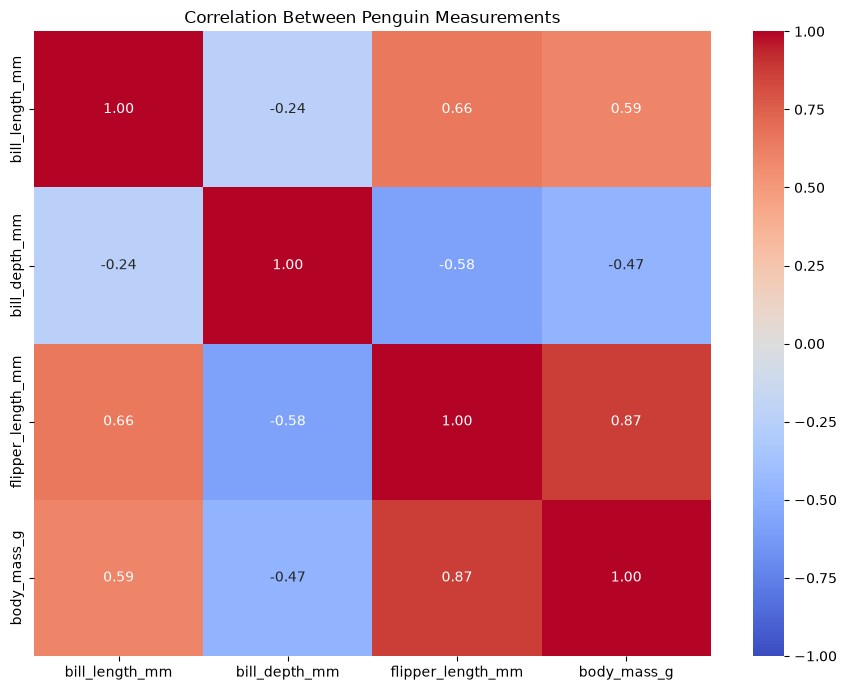

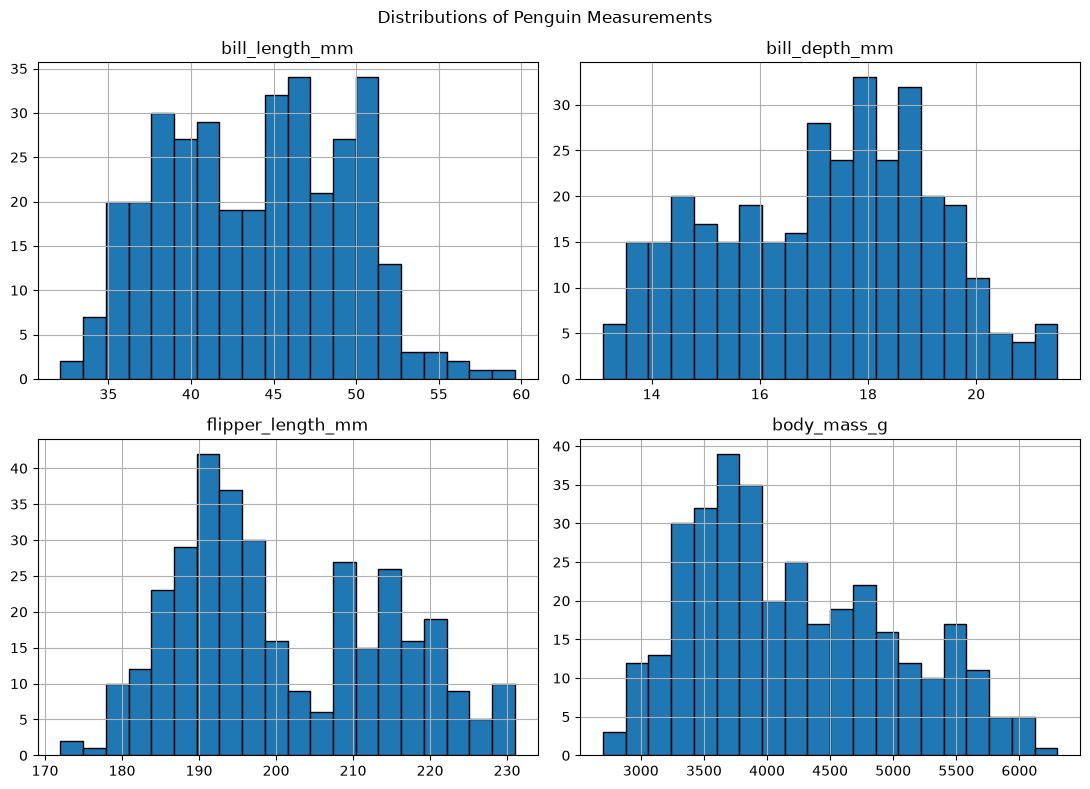

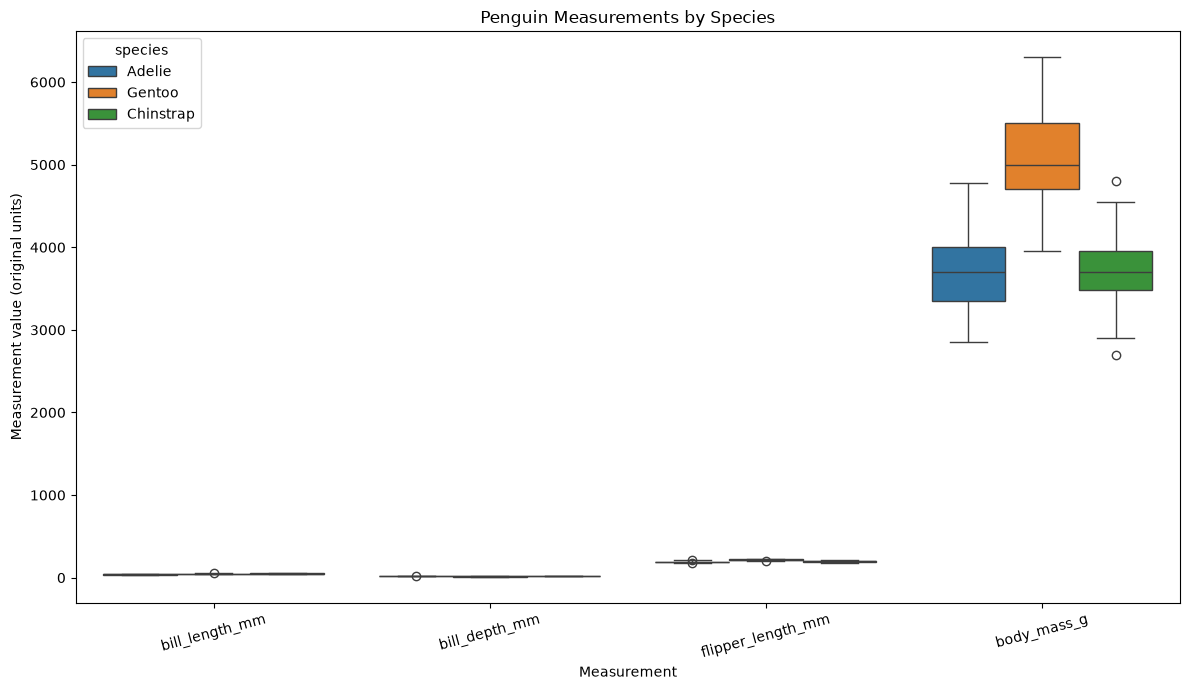

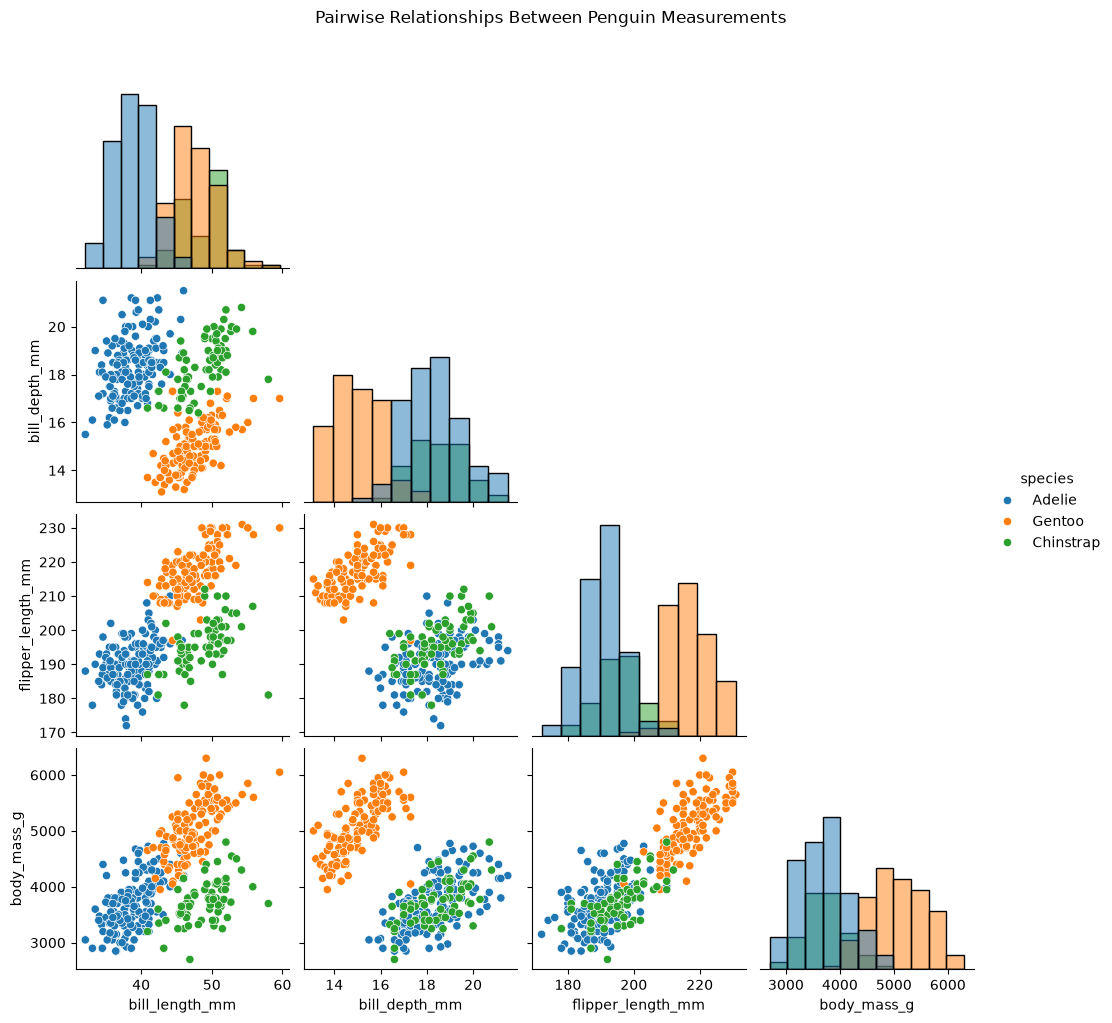

All four visualizations created and saved.

Correlation matrix:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
bill_length_mm,1.000,-0.235,0.656,0.595
bill_depth_mm,-0.235,1.000,-0.584,-0.472
flipper_length_mm,0.656,-0.584,1.000,0.871
body_mass_g,0.595,-0.472,0.871,1.000



Mean measurements by species:


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
species,,,,
Adelie,38.83,18.34,190.00,3702.96
Chinstrap,48.83,18.42,195.82,3733.09
Gentoo,47.48,15.00,217.02,5067.74


In [3]:

# 1. Correlation heatmap
correlation = cleaned[measurements].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
)
plt.title("Correlation Between Penguin Measurements")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "01_correlation_heatmap.png", dpi=300)
plt.show()
plt.close()

# 2. Feature distributions
cleaned[measurements].hist(
    figsize=(11, 8),
    bins=20,
    edgecolor="black",
)
plt.suptitle("Distributions of Penguin Measurements")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "02_feature_distributions.png", dpi=300)
plt.show()
plt.close("all")

# 3. Boxplots by species
plot_data = cleaned.melt(
    id_vars="species",
    value_vars=measurements,
    var_name="measurement",
    value_name="value",
)

plt.figure(figsize=(12, 7))
sns.boxplot(
    data=plot_data,
    x="measurement",
    y="value",
    hue="species",
)
plt.title("Penguin Measurements by Species")
plt.xlabel("Measurement")
plt.ylabel("Measurement value (original units)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "03_boxplots_by_species.png", dpi=300)
plt.show()
plt.close()

# 4. Pairwise scatterplots
pair_columns = measurements + ["species"]

pair_plot = sns.pairplot(
    cleaned[pair_columns],
    hue="species",
    diag_kind="hist",
    corner=True,
)
pair_plot.fig.suptitle(
    "Pairwise Relationships Between Penguin Measurements",
    y=1.02,
)
pair_plot.savefig(
    FIGURE_DIR / "04_pairwise_scatterplots.png",
    dpi=300,
)
plt.show()
plt.close("all")

print("All four visualizations created and saved.")

print("\nCorrelation matrix:")
display(correlation.round(3))

print("\nMean measurements by species:")
display(cleaned.groupby("species")[measurements].mean().round(2))



## Findings and Practical Interpretation

### 1. Correlation Heatmap
The heatmap shows the strength and direction of linear relationships between numerical measurements. A positive correlation means two measurements tend to increase together; a negative correlation means one tends to decrease as the other increases. Correlation does not establish causation.

### 2. Feature Distributions
The histograms show how bill length, bill depth, flipper length, and body mass are distributed. Differences in spread, skewness, and peaks can help identify variation within the dataset and guide further investigation.

### 3. Boxplots by Species
The boxplots compare the distribution and median of each measurement across Adelie, Chinstrap, and Gentoo penguins. Differences between species can help explain why species labels are useful when exploring physical measurements.

### 4. Pairwise Scatterplots
The scatterplots show relationships between pairs of measurements and distinguish species by color. Clusters or trends may indicate that some measurements help differentiate species. Any interpretation should be supported by the displayed data.

### Data Cleaning Decisions
The dataset initially contained 19 missing cells. Numerical missing values were filled using column medians, while categorical missing values were filled using the most frequent category. Exact duplicate rows were removed if present. Potential outliers were assessed with the 1.5 × IQR rule and were not automatically removed.

### Limitations
Median and mode imputation can reduce the visible variation in a dataset and may influence relationships between features. The imputed values should therefore be considered when interpreting the charts. Outlier detection identifies unusual values, not necessarily errors.


## Results and Key Observations

### Dataset Quality
The original dataset contains 344 rows and 8 columns. The missing-value check identified 19 missing cells: 2 each in bill length, bill depth, flipper length, and body mass, plus 11 in sex. No duplicate rows were found.

### Missing-Value Treatment
Missing numerical values were filled with their column medians. Missing categorical values were filled with the mode. The cleaned dataset contains zero missing cells. Imputation allows the analysis to continue while preserving the dataset's rows, but it can influence distributions and correlations.

### Outlier Detection
Potential outliers were assessed using the 1.5 × IQR rule for bill length, bill depth, flipper length, and body mass. The analysis detected zero potential outliers in these measurements, so none were removed.

### Species Comparison
The mean body mass was approximately:
- **Adelie:** 3,702.96 g
- **Chinstrap:** 3,733.09 g
- **Gentoo:** 5,067.74 g

Gentoo penguins had the highest average body mass among the three species in this dataset.

### Visualization Interpretation
The correlation heatmap and pairwise scatterplots should be used together to assess relationships between numerical measurements. The species boxplots and distribution histograms help compare variation and typical measurements. Specific correlation strengths should be reported from the calculated correlation matrix rather than estimated from the plots.

### Conclusion
This analysis demonstrates data profiling, missing-value treatment, duplicate checks, IQR-based outlier detection, and four required visualization types. The results show differences in average body mass between species. Findings are descriptive and do not establish causation.